# Notebook 60 — Conditional guidance and diffusion systems

[Notebook 59](./59_diffusion_intuition_and_rectified_flow.ipynb) learned an unconditional velocity field: it could generate a plausible point, but we could not request a particular mode. Here we add a class condition and use **classifier-free guidance** to control how strongly sampling follows it.

The practical experiment remains two-dimensional so that every effect is visible. The final sections then connect the same ideas to latent diffusion, text conditioning, U-Nets, and diffusion Transformers without attempting expensive image-scale training.

Related notes:

- [Conditional generation and classifier-free guidance](../notes/14-generative-models/conditional-generation-and-guidance.md)
- [Latent diffusion and modern generative systems](../notes/14-generative-models/latent-diffusion-and-modern-systems.md)

## Learning goals

- turn unconditional generation into class-conditional generation;
- represent a discrete condition with an embedding;
- understand why classifier-free guidance needs null-condition training;
- combine conditional and unconditional predictions during sampling;
- observe the condition-strength versus diversity trade-off;
- understand why modern systems often generate in latent space;
- distinguish the complete diffusion pipeline from its U-Net or Transformer backbone.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from cs231n_practice.generative import make_rectified_flow_pairs

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cpu")
print("device:", DEVICE)

device: cpu


## 1. Give every data mode a condition

The eight clusters now have labels from 0 through 7. Instead of learning only the marginal distribution $p(x)$, the model will learn the conditional distribution

$$
p(x\mid y),
$$

where $y$ is the requested mode label. The condition could instead be text, another image, a segmentation mask, or audio; class IDs are simply the clearest small example.

### Exercise 1 — Return both samples and their mode labels

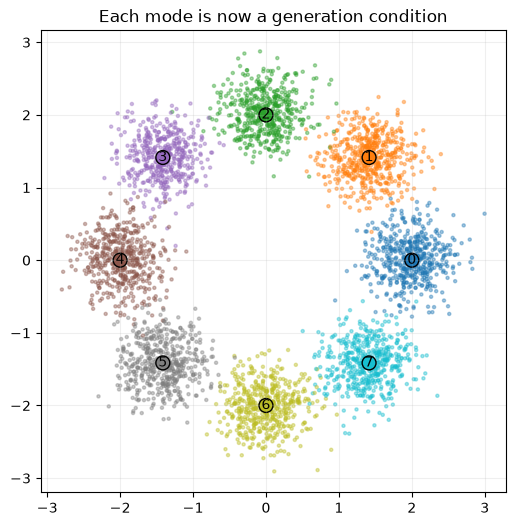

In [ ]:
NUMBER_CONDITIONS = 8
NULL_CONDITION = NUMBER_CONDITIONS
DATA_RADIUS = 2.0
CLUSTER_STD = 0.3
DATA_DIM = 2

angles = torch.linspace(0, 2 * torch.pi, NUMBER_CONDITIONS + 1)[:-1]
MODE_CENTERS = DATA_RADIUS * torch.stack(
    (torch.cos(angles), torch.sin(angles)),
    dim=1,
)


def sample_labeled_data(batch_size, *, device=DEVICE):
    # sample integer mode labels with shape (N,).
    labels = torch.randint(0, NUMBER_CONDITIONS, (batch_size,), device=device)
    # select their centers and add two-dimensional Gaussian noise.
    samples = MODE_CENTERS[labels] + CLUSTER_STD * torch.randn(batch_size, DATA_DIM, device=device)
    return samples, labels


data_examples, label_examples = sample_labeled_data(4000)
assert data_examples.shape == (4000, 2)
assert label_examples.shape == (4000,)
assert label_examples.dtype == torch.long
assert torch.all((label_examples >= 0) & (label_examples < NUMBER_CONDITIONS))

plt.figure(figsize=(6, 6))
plt.scatter(*data_examples.T, c=label_examples, cmap="tab10", s=5, alpha=0.4)
plt.scatter(*MODE_CENTERS.T, c=range(NUMBER_CONDITIONS), cmap="tab10", s=100, edgecolor="black")
for label, center in enumerate(MODE_CENTERS):
    plt.text(center[0], center[1], str(label), ha="center", va="center")
plt.axis("equal")
plt.title("Each mode is now a generation condition")
plt.grid(alpha=0.2)
plt.show()

## 2. Add a condition embedding

An embedding table converts each integer condition into a learned vector. We reserve one additional row for the special null condition $\varnothing$:

```text
mode labels:       0, 1, ..., 7
null condition:    8
embedding lookup:  (N,) -> (N, condition_dim)
```

For every example, the velocity network receives its 2D position, scalar time, and condition embedding. The embedding width is an internal feature width; it is not the number of classes.

### Exercise 2 — Combine position, time, and condition features

In [5]:
class ConditionalVelocityMLP(nn.Module):
    def __init__(self, hidden_dim=128, condition_dim=16):
        super().__init__()
        self.condition_embedding = nn.Embedding(NUMBER_CONDITIONS + 1, condition_dim)
        self.network = nn.Sequential(
            nn.Linear(DATA_DIM + 1 + condition_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, DATA_DIM),
        )

    def forward(self, positions, times, conditions):
        # look up one condition embedding per example.
        condition_features = self.condition_embedding(conditions)
        # concatenate positions, times, and condition features along the feature axis.
        model_inputs = torch.cat([positions, times, condition_features], dim=-1)
        return self.network(model_inputs)


shape_model = ConditionalVelocityMLP(hidden_dim=32, condition_dim=6)
shape_positions = torch.randn(5, 2)
shape_times = torch.rand(5, 1)
shape_conditions = torch.tensor([0, 1, 2, 7, NULL_CONDITION])
shape_velocities = shape_model(shape_positions, shape_times, shape_conditions)
assert shape_model.condition_embedding(shape_conditions).shape == (5, 6)
assert shape_velocities.shape == shape_positions.shape

## 3. Why train with a null condition?

Classifier-free guidance needs the same network to make two predictions:

- $v_{cond}$: a prediction using the requested condition;
- $v_{uncond}$: a prediction using no condition.

A model trained only with labels 0–7 would never learn what the null embedding means. During training, we therefore replace the true label with `NULL_CONDITION` for a random fraction of examples. This is called **condition dropout**. It drops conditioning information, not neural activations.

A dropout probability such as 0.15 means that roughly 15% of training examples teach the unconditional behavior and the remaining examples teach conditional behavior.

### Exercise 3 — Apply condition dropout

In [6]:
def drop_conditions(conditions, probability, *, null_condition=NULL_CONDITION):
    # independently choose which batch elements lose their condition.
    drop_mask = torch.rand_like(conditions.float()) < probability
    # replace selected labels with the null-condition ID.
    conditions = conditions.where(~drop_mask, torch.tensor(null_condition, device=conditions.device))
    return conditions


test_conditions = torch.arange(NUMBER_CONDITIONS)
torch.testing.assert_close(drop_conditions(test_conditions, 0.0), test_conditions)
torch.testing.assert_close(
    drop_conditions(test_conditions, 1.0),
    torch.full_like(test_conditions, NULL_CONDITION),
)
torch.manual_seed(SEED)
many_conditions = torch.arange(1000) % NUMBER_CONDITIONS
dropped = drop_conditions(many_conditions, 0.15)
observed_fraction = (dropped == NULL_CONDITION).float().mean().item()
print(f"observed null-condition fraction: {observed_fraction:.3f}")
assert 0.10 < observed_fraction < 0.20

observed null-condition fraction: 0.156


## 4. Train conditional and unconditional behavior together

Flow pairs are constructed exactly as [before](./59_diffusion_intuition_and_rectified_flow.ipynb):

$$
x_t=x_{noise}+t(x_{data}-x_{noise}),
\qquad
v_{target}=x_{data}-x_{noise}.
$$

The only addition is that the network sometimes receives the data label and sometimes the null label. Both behaviors are learned with one velocity-regression objective.

### Exercise 4 — Implement the conditional flow loss

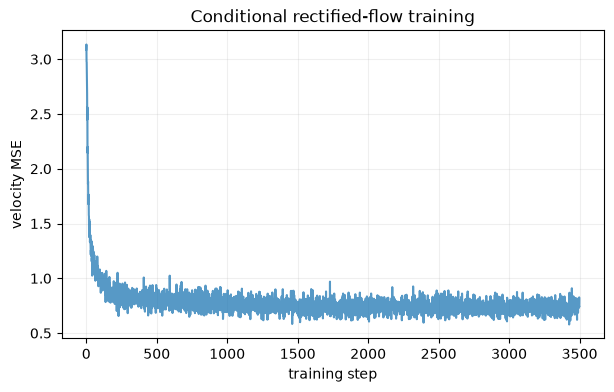

In [8]:
def conditional_flow_loss(model, batch_size, condition_dropout=0.15):
    data, conditions = sample_labeled_data(batch_size)
    # construct interpolated positions, times, and target velocities.
    interpolated, times, target_velocity = make_rectified_flow_pairs(data)
    # randomly replace some real conditions with the null condition.
    model_conditions = drop_conditions(conditions, condition_dropout)
    # predict velocity and return mean squared error.
    predicted_velocity = model(interpolated, times, model_conditions)
    return F.mse_loss(predicted_velocity, target_velocity)


def train_conditional_flow(steps=3500, batch_size=512, learning_rate=2e-3, seed=SEED):
    torch.manual_seed(seed)
    model = ConditionalVelocityMLP().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []

    model.train()
    for _ in range(steps):
        optimizer.zero_grad()
        loss = conditional_flow_loss(model, batch_size)
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    return model, history


conditional_model, training_history = train_conditional_flow()
assert len(training_history) == 3500
assert np.isfinite(training_history).all()

plt.figure(figsize=(7, 4))
plt.plot(training_history, alpha=0.75)
plt.xlabel("training step")
plt.ylabel("velocity MSE")
plt.title("Conditional rectified-flow training")
plt.grid(alpha=0.2)
plt.show()

## 5. Classifier-free guidance

At each sampling step, the same network is evaluated twice:

$$
v_{uncond}=v_\theta(x_t,t,\varnothing),
\qquad
v_{cond}=v_\theta(x_t,t,y).
$$

We use the guidance-scale convention

$$
v_{guided}=v_{uncond}+w(v_{cond}-v_{uncond}).
$$

Its useful reference points are:

- $w=0$: unconditional prediction;
- $w=1$: ordinary conditional prediction;
- $w>1$: extrapolate beyond the conditional prediction, strengthening the condition;
- very large $w$: potentially stronger adherence but lower diversity or distorted samples.

Some sources instead report an **extra guidance strength** $s=w-1$ and write $v_{cond}+s(v_{cond}-v_{uncond})$. Always check the convention before comparing numerical values.

### Exercise 5 — Combine the two velocity predictions

In [9]:
def guided_velocity(model, positions, times, conditions, guidance_scale):
    null_conditions = torch.full_like(conditions, NULL_CONDITION)
    # calculate conditional and unconditional predictions.
    conditional_velocity = model(positions, times, conditions)
    unconditional_velocity = model(positions, times, null_conditions)
    # amplify the condition-induced difference using guidance_scale.
    return unconditional_velocity + guidance_scale * (conditional_velocity - unconditional_velocity)


test_positions = torch.randn(6, 2)
test_times = torch.rand(6, 1)
test_conditions = torch.arange(6)
conditional_prediction = conditional_model(test_positions, test_times, test_conditions)
unconditional_prediction = conditional_model(
    test_positions,
    test_times,
    torch.full_like(test_conditions, NULL_CONDITION),
)
torch.testing.assert_close(
    guided_velocity(conditional_model, test_positions, test_times, test_conditions, 0.0),
    unconditional_prediction,
)
torch.testing.assert_close(
    guided_velocity(conditional_model, test_positions, test_times, test_conditions, 1.0),
    conditional_prediction,
)

## 6. Conditional Euler sampling

The Euler update is unchanged except that its velocity is now guided:

$$
x_{k+1}=x_k+\Delta t\,v_{guided}(x_k,t_k,y).
$$

Every sample keeps the same requested condition throughout its trajectory. Its position $x_k$ and time $t_k$ change at each Euler step, but its condition $y$ does not. The model therefore recomputes a condition-dependent velocity $v_{guided}(x_k,t_k,y)$ at every new position. Together, these velocities form the **learned vector field** that tells samples where to move at different positions and times.

The condition does not select or copy a stored training example. Sampling begins from a fresh random noise point, and the fixed condition continuously steers that point toward the requested part of the learned data distribution. Different initial noise points can consequently produce different samples for the same condition.

### Exercise 6 — Implement guided Euler sampling

In [10]:
@torch.no_grad()
def sample_conditional_flow(model, initial_noise, conditions, number_steps=50, guidance_scale=1.0):
    model.eval()
    positions = initial_noise.clone()
    step_width = 1.0 / number_steps

    for step in range(number_steps):
        # make a time tensor with shape (N, 1).
        times = torch.full((len(positions), 1), step * step_width, device=DEVICE)
        # obtain the guided velocity and take one Euler step.
        velocity = guided_velocity(model, positions, times, conditions, guidance_scale)
        positions = positions + velocity * step_width
    return positions


class ConstantConditionalVelocity(nn.Module):
    def forward(self, positions, times, conditions):
        return torch.stack((conditions.float(), -conditions.float()), dim=1)


sampler_noise = torch.zeros(3, 2)
sampler_conditions = torch.tensor([0, 1, 2])
sampler_result = sample_conditional_flow(
    ConstantConditionalVelocity(),
    sampler_noise,
    sampler_conditions,
    number_steps=5,
    guidance_scale=1.0,
)
expected_result = torch.tensor([[0.0, 0.0], [1.0, -1.0], [2.0, -2.0]])
torch.testing.assert_close(sampler_result, expected_result)

## 7. Measure condition adherence and diversity

For this known distribution, a generated point follows its requested condition when its nearest center has that label. We will measure:

- **condition accuracy**: fraction assigned to the requested center;
- **target distance**: mean distance to the requested center;
- **within-condition spread**: mean distance from each condition's generated mean.

A large guidance scale may improve the first two values while shrinking the third. That illustrates the usual adherence-versus-diversity trade-off, although exact results depend on training.

### Exercise 7 — Compare several guidance scales

w=0.00: condition accuracy=0.129, target distance=2.584, spread=1.939
w=0.25: condition accuracy=0.278, target distance=1.611, spread=1.397
w=0.50: condition accuracy=0.548, target distance=0.914, spread=0.849
w=0.75: condition accuracy=0.863, target distance=0.545, spread=0.526
w=1.00: condition accuracy=0.987, target distance=0.376, spread=0.372
w=1.25: condition accuracy=0.999, target distance=0.313, spread=0.300
w=2.00: condition accuracy=1.000, target distance=0.421, spread=0.244
w=4.00: condition accuracy=1.000, target distance=1.166, spread=0.164


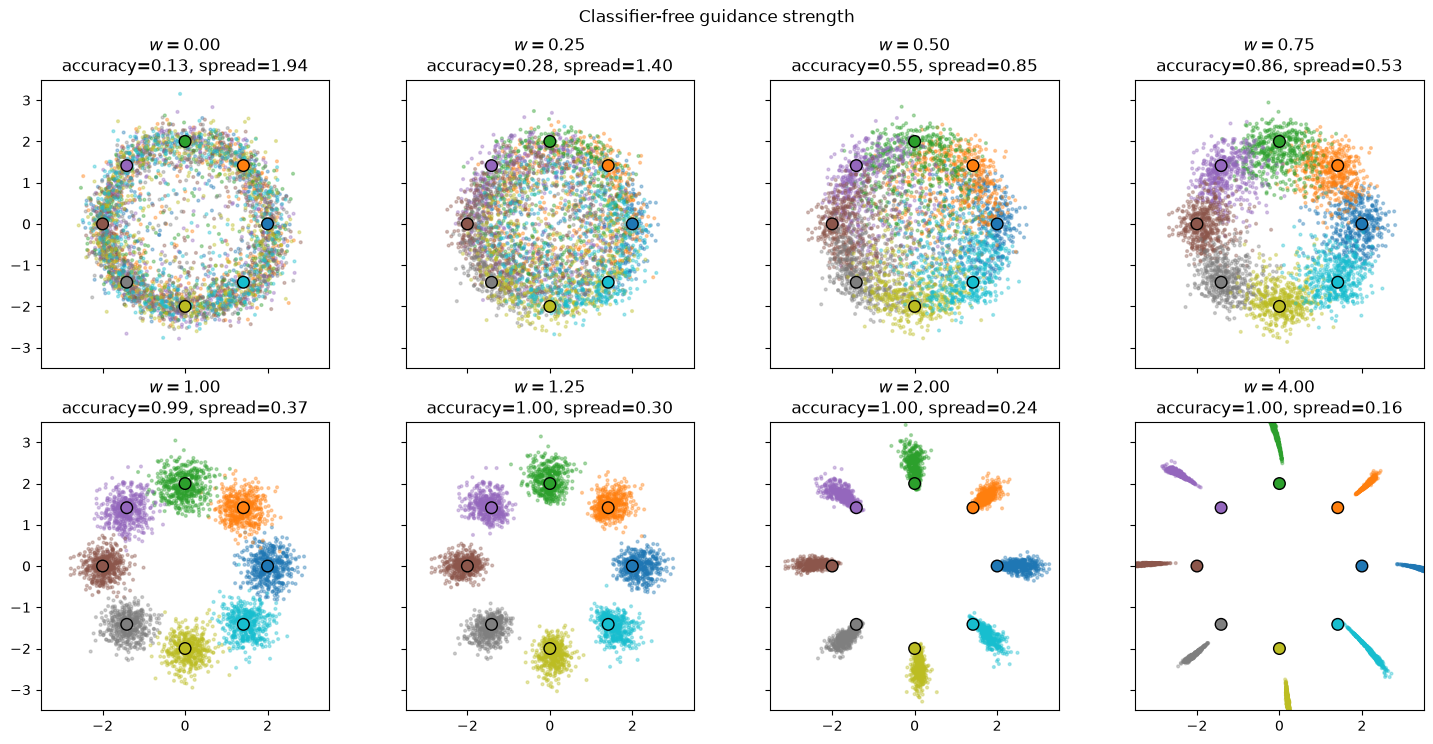

In [16]:
def conditional_statistics(points, conditions):
    centers = MODE_CENTERS.to(points.device)
    distances = torch.cdist(points, centers)
    nearest_conditions = distances.argmin(dim=1)
    accuracy = (nearest_conditions == conditions).float().mean().item()
    target_distance = torch.linalg.vector_norm(
        points - centers[conditions], dim=1
    ).mean().item()

    spreads = []
    for condition in range(NUMBER_CONDITIONS):
        group = points[conditions == condition]
        spreads.append(torch.linalg.vector_norm(group - group.mean(dim=0), dim=1).mean())
    mean_spread = torch.stack(spreads).mean().item()
    return accuracy, target_distance, mean_spread


samples_per_condition = 500
requested_conditions = torch.arange(NUMBER_CONDITIONS).repeat_interleave(samples_per_condition)
torch.manual_seed(SEED + 1)
shared_noise = torch.randn(len(requested_conditions), DATA_DIM)
guidance_scales = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 2.0, 4.0]
guided_results = {}

for scale in guidance_scales:
    points = sample_conditional_flow(
        conditional_model, shared_noise, requested_conditions, guidance_scale=scale
    )
    statistics = conditional_statistics(points, requested_conditions)
    guided_results[scale] = (points, statistics)
    accuracy, distance, spread = statistics
    print(
        f"w={scale:.2f}: condition accuracy={accuracy:.3f}, "
        f"target distance={distance:.3f}, spread={spread:.3f}"
    )

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5), sharex=True, sharey=True)
for axis, scale in zip(axes.flat, guidance_scales):
    points, (accuracy, _, spread) = guided_results[scale]
    axis.scatter(*points.T, c=requested_conditions, cmap="tab10", s=4, alpha=0.35)
    axis.scatter(*MODE_CENTERS.T, c=range(NUMBER_CONDITIONS), cmap="tab10", s=70, edgecolor="black")
    axis.set_title(f"$w={scale:.2f}$\naccuracy={accuracy:.2f}, spread={spread:.2f}")
    axis.set_aspect("equal")
    axis.set_xlim(-3.5, 3.5)
    axis.set_ylim(-3.5, 3.5)
plt.suptitle("Classifier-free guidance strength")
plt.tight_layout()
plt.show()

## 8. From pixels to latent diffusion

Repeatedly processing a high-resolution image is expensive. Latent diffusion separates compression from generation:

```text
training image -> encoder -> clean latent
noise latent -> repeated conditioned updates -> generated latent -> decoder -> image
```

The encoder and decoder form an image autoencoder, usually trained before the generative model. During generative training, images are encoded and the diffusion or flow objective is applied to their latents. During generation, sampling starts from random latent noise, so the image encoder is not needed; the decoder turns the final latent into pixels.

If a $512\times512$ image is compressed by a factor of eight along height and width, the latent grid is $64\times64$. It has 64 times fewer spatial positions:

$$
\frac{512\cdot512}{64\cdot64}=64.
$$

Without spatial compression, a pixel-space model would process $512\cdot512=262{,}144$ spatial positions instead of $4{,}096$. If both grids were divided into $2\times2$ patches, pixel space would produce $65{,}536$ tokens while latent space would produce $1{,}024$ tokens—again a 64-fold reduction in token count.

The latent has four channels rather than the image's three RGB channels, so the exact number of stored scalar values changes from $3\cdot512\cdot512=786{,}432$ to $4\cdot64\cdot64=16{,}384$, a 48-fold reduction. Spatial or token count is especially important for attention because self-attention compares token pairs, while channel width affects each token's feature size. Information discarded by the autoencoder cannot be recovered by a perfect latent generator.

### Exercise 8 — Calculate latent and token shapes

In [18]:
image_channels = 3
image_height = image_width = 512
spatial_downsampling = 8
latent_channels = 4
patch_size = 2

# calculate the latent height and width.
latent_height = image_height // spatial_downsampling
latent_width = image_width // spatial_downsampling
# Compare uncompressed pixel positions with compressed latent positions.
pixel_positions = image_height * image_width
latent_positions = latent_height * latent_width
spatial_position_reduction = pixel_positions / latent_positions
# Compare equal-size patchification before and after spatial compression.
number_pixel_tokens = (image_height // patch_size) * (image_width // patch_size)
number_latent_tokens = latent_positions // (patch_size ** 2)
token_reduction = number_pixel_tokens / number_latent_tokens
# Channel counts determine the scalar values stored in each representation.
pixel_values = image_channels * pixel_positions
latent_values = latent_channels * latent_positions
scalar_value_reduction = pixel_values / latent_values
pixel_values_per_patch = image_channels * (patch_size ** 2)
latent_values_per_patch = latent_channels * (patch_size ** 2)

assert (latent_height, latent_width) == (64, 64)
assert (pixel_positions, latent_positions) == (262144, 4096)
assert spatial_position_reduction == 64
assert number_pixel_tokens == 65536
assert number_latent_tokens == 1024
assert token_reduction == 64
assert (pixel_values, latent_values) == (786432, 16384)
assert scalar_value_reduction == 48
assert (pixel_values_per_patch, latent_values_per_patch) == (12, 16)
print(
    f"pixel space:  {image_channels} x {image_height} x {image_width} "
    f"= {pixel_positions:,} positions, {pixel_values:,} scalar values\n"
    f"latent space: {latent_channels} x {latent_height} x {latent_width} "
    f"= {latent_positions:,} positions, {latent_values:,} scalar values\n"
    f"spatial positions: {spatial_position_reduction:.0f}x fewer\n"
    f"equal 2x2 patchification: {number_pixel_tokens:,} pixel tokens versus "
    f"{number_latent_tokens:,} latent tokens ({token_reduction:.0f}x fewer)\n"
    f"total scalar values: {scalar_value_reduction:.0f}x fewer in latent space\n"
    f"values per 2x2 patch: {pixel_values_per_patch} in RGB space versus "
    f"{latent_values_per_patch} in latent space"
)

pixel space:  3 x 512 x 512 = 262,144 positions, 786,432 scalar values
latent space: 4 x 64 x 64 = 4,096 positions, 16,384 scalar values
spatial positions: 64x fewer
equal 2x2 patchification: 65,536 pixel tokens versus 1,024 latent tokens (64x fewer)
total scalar values: 48x fewer in latent space
values per 2x2 patch: 12 in RGB space versus 16 in latent space


## 9. U-Net and DiT are backbones, not complete pipelines

For a broader description of the complete pipeline and the role of each component, see [Latent diffusion and modern generative systems](../notes/14-generative-models/latent-diffusion-and-modern-systems.md).

The iterative generator needs a neural network to predict noise, velocity, or another update target. Two common backbone families are:

| Backbone | Main representation | Useful bias | Typical conditioning mechanisms |
| --- | --- | --- | --- |
| U-Net | Spatial feature maps at several resolutions | Locality and multiscale image structure | Time embeddings, cross-attention, feature modulation |
| Diffusion Transformer (DiT) | Patches of the noisy latent as tokens | Flexible global token interactions | Adaptive normalization, cross-attention, joint condition tokens |

A DiT replaces the denoising or velocity-prediction backbone; it does not replace the scheduler, conditioning encoder, latent autoencoder, or decoder. The high-level latent pipeline remains:

```text
prompt -> text encoder -> condition embeddings -------------------+
                                                                 |
random latent -> repeated U-Net or DiT updates -> clean latent -> decoder -> image
```

Text conditioning is richer than the single class embedding used above. A text encoder normally returns a sequence of token representations. Cross-attention or joint attention lets image-latent features repeatedly read the relevant prompt tokens during generation.

## 10. What this toy experiment leaves out

Modern image systems additionally depend on large datasets, powerful image autoencoders, rich time embeddings, text encoders, careful noise or flow schedules, advanced numerical solvers, large U-Nets or Transformers, and substantial compute. Video systems add a temporal latent axis and must preserve consistency across frames.

Sampling can remain expensive because the backbone may be evaluated tens of times. Distillation methods train a student to approximate several teacher updates with fewer evaluations. This improves speed but may introduce quality, diversity, or training-complexity trade-offs.

The invariant worth remembering is simpler: the model receives a current noisy state, time, and optional condition; it predicts a useful update; repeated updates transform a simple noise sample into structured data.

## Reflection

Answer briefly after completing and running the notebook.

1. How does conditional generation differ from unconditional generation?

   **Answer:** Conditional generation receives additional information such as a class label or text prompt and models $p(x\mid y)$. Unconditional generation models $p(x)$ without requesting a particular kind of output.

2. Why does the embedding table contain nine rows for eight real conditions?

   **Answer:** Eight rows represent the real conditions, and the ninth represents the null condition. The null embedding lets the same network produce an unconditional prediction for classifier-free guidance.

3. Why must the model encounter the null condition during training?

   **Answer:** The model must encounter the null condition so it learns meaningful unconditional velocities. Otherwise, its null-condition prediction during guidance would be untrained and unreliable. Diversity is a possible effect of guidance strength, but it is not the primary reason for null-condition training.

4. Under this notebook's guidance convention, what do $w=0$, $w=1$, and $w>1$ mean?

   **Answer:** Under this convention:
- $w=0$: unconditional prediction;
- $w=1$: ordinary conditional prediction;
- $w>1$: extrapolation beyond the conditional prediction, strengthening the condition.

5. What adherence-versus-diversity pattern did your guidance experiment show?

   **Answer:** Increasing guidance improved adherence and reduced spread. In this run, w=1.25 gave the smallest target distance. Stronger guidance eventually became harmful: at w=4, samples were less diverse and farther from their target centers.

6. Why can latent diffusion be much cheaper than pixel-space diffusion?

   **Answer:** Latent diffusion processes a much smaller spatial grid, reducing activation memory and computation—especially attention computation. It does not automatically imply fewer model parameters, because parameter count also depends on the chosen architecture.

7. Which components are used during latent-diffusion training, and which are used during generation?

   **Answer:** 
   - Autoencoder pretraining: encoder and decoder.
   - Generative-model training: frozen encoder converts images to latents; the denoising or flow model learns on those latents. The decoder is normally unnecessary for the training loss.
   - Generation: denoising or flow model transforms random latent noise, then the decoder produces an image. The image encoder is unnecessary.
8. What does a DiT replace, and what parts of the complete generative system remain?

   **Answer:** A DiT replaces the U-Net-style denoising or velocity-prediction backbone. The latent autoencoder, decoder, text encoder, time and condition inputs, sampling schedule, iterative solver, and guidance mechanism remain parts of the complete system.